# Conversational Search Retrieval Augmented Generation

In this notebook you will implement the following steps:

- **Answer selection + evaluation**: Implement a *search-based* conversation framework evaluation framework to evaluate conversation topics made up of conversation turns.
- **Answer ranking**: Implement a *re-ranking method* to sort the initial search results. Evaluate the re-ranked results.
- **Conversation memory**: Implement a conversational context modeling method to keep track of the conversation state. 

Submission dates:
- **20 October**: first stage retrieval + conversation memory + evaluation
- **15 November**: re-ranking with LLM + evaluation
- **15 December**: answer generation + evaluation

## Test bed and conversation topics
The TREC CAST corpus (http://www.treccast.ai/) for Conversational Search is indexed in this cluster and available to be searched behind an OpenSearch API.

The queries and the relevance judgments are available through class `ConvSearchEvaluation`:

In [1]:
from importlib import reload
import TRECCASTeval as trec
import numpy as np
import pprint

import numpy as np

pp = pprint.PrettyPrinter(indent=4)

test_bed = trec.ConvSearchEvaluation()

print()
print("========================================== Training conversations =====")
topics = {}
for topic in test_bed.train_topics:
    conv_id = topic['number']

    if conv_id not in (1, 2, 4, 7, 15, 17,18,22,23,24,25,27,30):
        continue

    print()
    print(conv_id, "  ", topic['title'])

    for turn in topic['turn']:
        turn_id = turn['number']
        utterance = turn['raw_utterance']
        topic_turn_id = '%d_%d'% (conv_id, turn_id)
        
        print(topic_turn_id, utterance)
        topics[topic_turn_id] = utterance

print()
print("========================================== Test conversations =====")
for topic in test_bed.test_topics:
    conv_id = topic['number']

    if conv_id not in (31, 32, 33, 34, 37, 40, 49, 50, 54, 56, 58, 59, 61, 67, 68, 69, 75, 77, 78, 79):
        continue

    print()
    print(conv_id, "  ", topic['title'])

    for turn in topic['turn']:
        turn_id = turn['number']
        utterance = turn['raw_utterance']
        topic_turn_id = '%d_%d'% (conv_id, turn_id)
        
        print(topic_turn_id, utterance)
        topics[topic_turn_id] = utterance



========================================== Training conversations =====

1    Career choice for Nursing and Physician's Assistant
1_1 What is a physician's assistant?
1_2 What are the educational requirements required to become one?
1_3 What does it cost?
1_4 What's the average starting salary in the UK?
1_5 What about in the US?
1_6 What school subjects are needed to become a registered nurse?
1_7 What is the PA average salary vs an RN?
1_8 What the difference between a PA and a nurse practitioner?
1_9 Do NPs or PAs make more?
1_10 Is a PA above a NP?
1_11 What is the fastest way to become a NP?
1_12 How much longer does it take to become a doctor after being an NP?

2    Goat breeds
2_1 What are the main breeds of goat?
2_2 Tell me about boer goats.
2_3 What breed is good for meat?
2_4 Are angora goats good for it?
2_5 What about boer goats?
2_6 What are pygmies used for?
2_7 What is the best for fiber production?
2_8 How long do Angora goats live?
2_9 Can you milk them?
2_10 How ma

## OpenSearch

In [2]:
import OpenSearchSimpleAPI as osearch
import pprint as pp
opensearch = osearch.OSsimpleAPI()

Search example:

In [ ]:
results = opensearch.search_body(topics['33_1'], numDocs = 10)
print(results)

In [ ]:
opensearch.doc_term_vectors('MARCO_34196')

In [ ]:
# sum_doc_freq: 
# doc_count: 
# sum_ttf: 
# doc_freq: 
# ttf: 
# term_freq: 
opensearch.termvectors_JSON(doc_id='MARCO_34196')

In [ ]:
opensearch.get_doc_body('MARCO_34196')

In [ ]:
example_doc = 'The film only adapts the first half of the book, and consequently does not convey the message of the title as it was portrayed in the novel. The second half of the book would subsequently be used as the rough basis for the second film, The NeverEnding Story II: The Next Chapter.The third film, The NeverEnding Story III: Escape From Fantasia, features a completely original plot.he second half of the book would subsequently be used as the rough basis for the second film, The NeverEnding Story II: The Next Chapter.'
opensearch.query_terms(example_doc,'standard')

In [ ]:
opensearch.analyzer(analyzer="standard", query=example_doc)

## Retrieval with training conversations
The OpenSearchSimpleAPI notebook illustrates how to use OpenSearch. Use this API to retrieve the top 100 ranked passages for each conversation turn. 

To evaluate the results you should use the provided `ConvSearchEvaluation` class. Examine and discuss the recall metric results. In terms of metrics, discuss what should be your goals for each step of the project.

In [3]:
from importlib import reload
import TRECCASTeval as trec
from textwrap import wrap
import OpenSearchSimpleAPI as osearch
import rank_with_history as rwh
import ReRankLMD as rr

import pprint as pp

osearch = reload(osearch)
trec = reload(trec)
rwh = rwh.rank_with_history()
rr = rr.ReRank()

opensearch = osearch.OSsimpleAPI()
test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.train_topics
selected_topics = (1, 2, 4, 7, 17,18,22,23,24,25,27,30)
fig_subplot_size = [3,4]

BM25

c:\Users\Goncalo\Documents\UNIVERSIDADE\4_Ano\1_Semestre\RI\RI-Project\1st Stage\NLPSearch-phase1\retrieval\BM25.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



P10= 0.15728155339805822   Recall= 0.6699724628122686   NDCG@5= 0.2088312547271504   AP= 0.22150690254001845



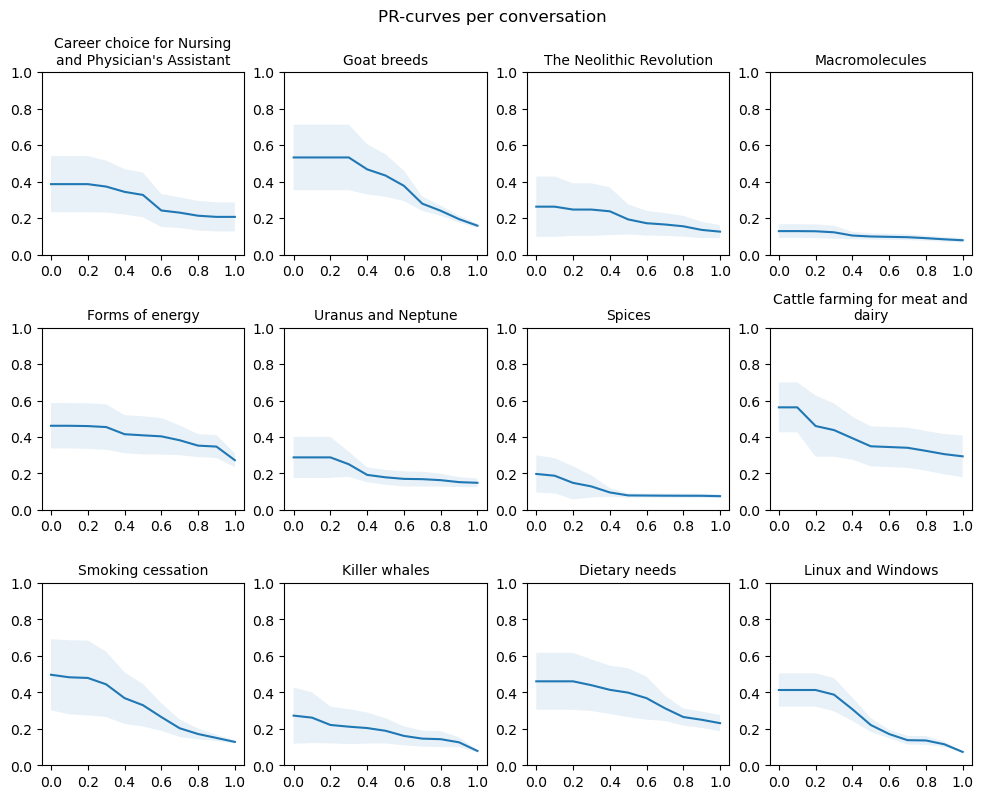

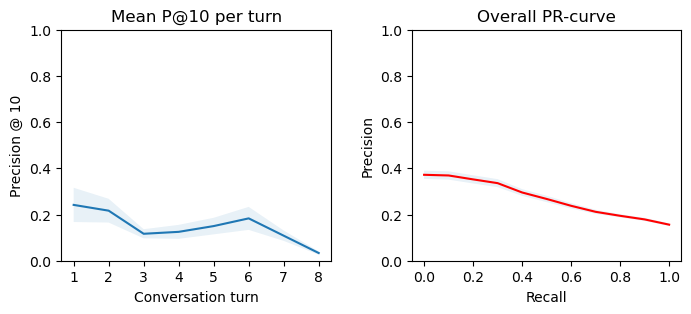

In [17]:
from retrieval.BM25 import BM25

bm25 = BM25(opensearch,test_bed,conv_topics,selected_topics)
bm25.run(fig_subplot_size)


LMD

In [ ]:
from retrieval.LMD import LMD

lmd = LMD(opensearch,test_bed,conv_topics,selected_topics)
lmd.run(fig_subplot_size)

Conversation History - Sliding Window

c:\Users\Goncalo\Documents\UNIVERSIDADE\4_Ano\1_Semestre\RI\RI-Project\1st Stage\NLPSearch-phase1\retrieval\ConversationHistory.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



QUERY: What is a physician's assistant?  What are the educational requirements required to become one?


QUERY: What is a physician's assistant? What are the educational requirements required to become one? What does it cost?


QUERY: What is a physician's assistant? What does it cost? What's the average starting salary in the UK?


QUERY: What is a physician's assistant? What's the average starting salary in the UK? What about in the US?


QUERY: What is a physician's assistant? What about in the US? What school subjects are needed to become a registered nurse?


QUERY: What is a physician's assistant? What school subjects are needed to become a registered nurse? What is the PA average salary vs an RN?


QUERY: What is a physician's assistant? What is the PA average salary vs an RN? What the difference between a PA and a nurse practitioner?


QUERY: What is a physician's assistant? What the difference between a PA and a nurse practitioner? Do NPs or PAs make more?


QUERY: What is a 

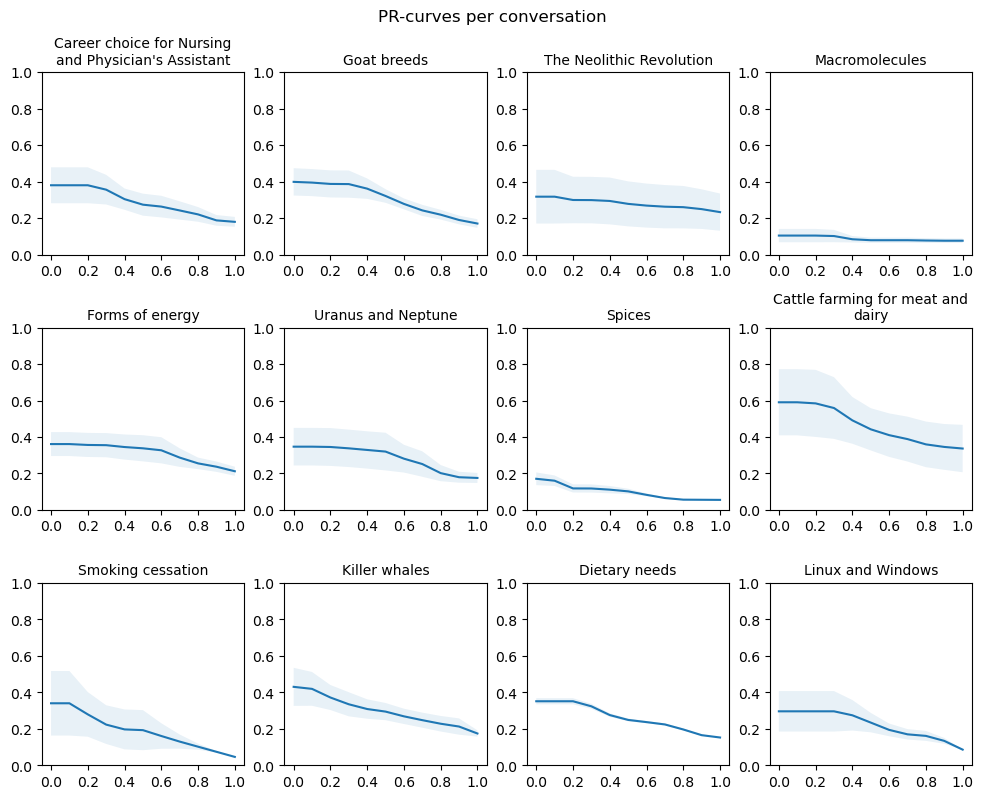

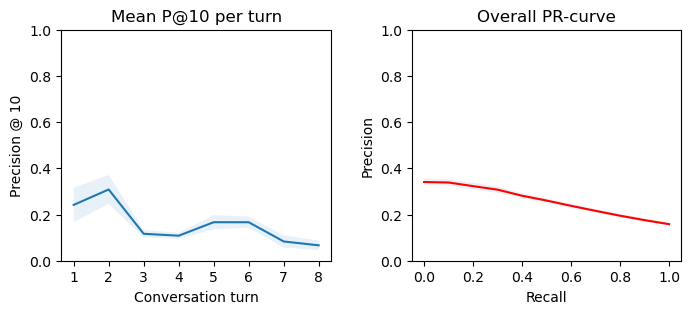

In [4]:
from retrieval.ConversationHistory import ConversationHistory

convHistory = ConversationHistory(opensearch,test_bed,conv_topics,selected_topics)
convHistory.run_sliding_window(fig_subplot_size)

Conversation History - First utterance only

c:\Users\Goncalo\Documents\UNIVERSIDADE\4_Ano\1_Semestre\RI\RI-Project\1st Stage\NLPSearch-phase1\retrieval\ConversationHistory.py:136: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



QUERY: What is a physician's assistant? What are the educational requirements required to become one?


QUERY: What is a physician's assistant? What does it cost?


QUERY: What is a physician's assistant? What's the average starting salary in the UK?


QUERY: What is a physician's assistant? What about in the US?


QUERY: What is a physician's assistant? What school subjects are needed to become a registered nurse?


QUERY: What is a physician's assistant? What is the PA average salary vs an RN?


QUERY: What is a physician's assistant? What the difference between a PA and a nurse practitioner?


QUERY: What is a physician's assistant? Do NPs or PAs make more?


QUERY: What is a physician's assistant? Is a PA above a NP?


QUERY: What is a physician's assistant? What is the fastest way to become a NP?


QUERY: What is a physician's assistant? How much longer does it take to become a doctor after being an NP?


QUERY: What are the main breeds of goat? Tell me about boer goats.


QUERY:

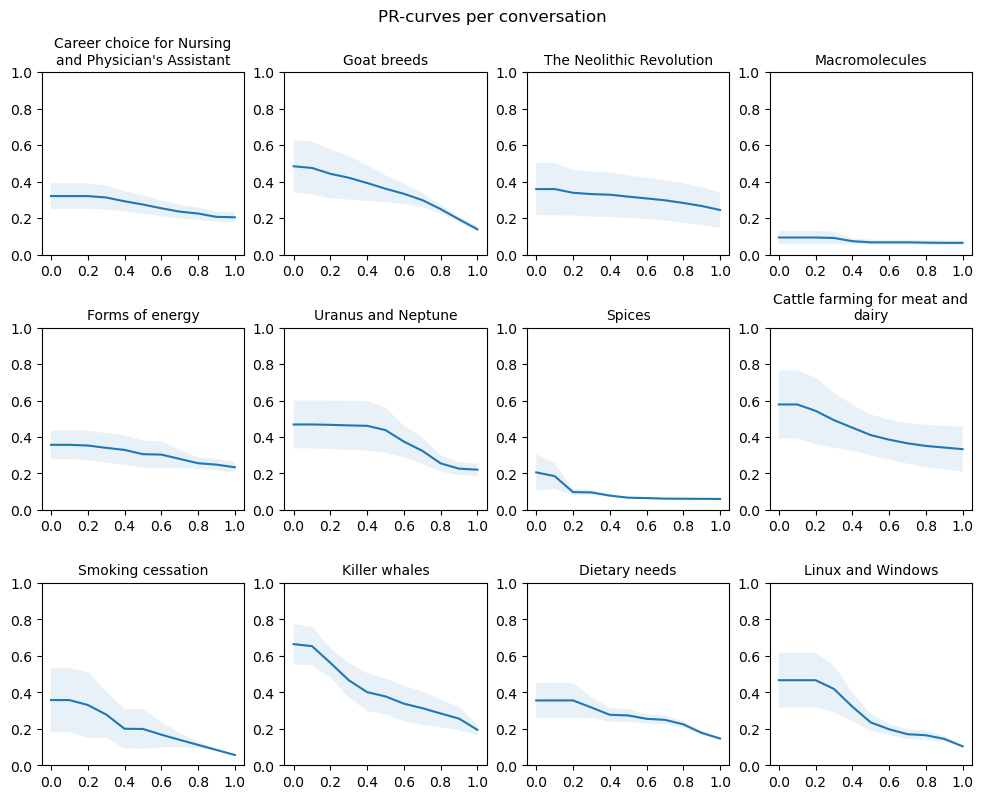

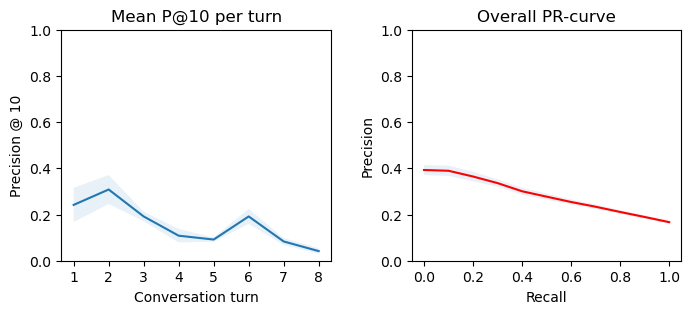

In [5]:
from retrieval.ConversationHistory import ConversationHistory

convHistory = ConversationHistory(opensearch,test_bed,conv_topics,selected_topics)
convHistory.run_first_utt_only(fig_subplot_size)

## Retrieval with the test conversations

In [6]:
from importlib import reload
import TRECCASTeval as trec
from textwrap import wrap
import OpenSearchSimpleAPI as osearch
import rank_with_history as rwh
import ReRank as rr

import pprint as pp

osearch = reload(osearch)
trec = reload(trec)
rwh = rwh.rank_with_history()
rr = rr.ReRank()

opensearch = osearch.OSsimpleAPI()

test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.test_topics
verbose = False
selected_topics = (31, 32, 33, 34, 37, 40, 49, 50, 54, 56, 58, 59, 61, 67, 68, 69, 75, 77, 78, 79)
fig_subplot_size = [5,4]

ModuleNotFoundError: No module named 'ReRank'

BM25

In [5]:
from retrieval.BM25 import BM25

bm25 = BM25(opensearch,test_bed,conv_topics,selected_topics)
bm25.run(fig_subplot_size)


AttributeError: module 'matplotlib.pyplot' has no attribute 'use'

LMD

In [ ]:
from retrieval.LMD import LMD

lmd = LMD(opensearch,test_bed,conv_topics,selected_topics)
lmd.run(fig_subplot_size)

Conversation History - Sliding Window

c:\Users\Goncalo\Documents\UNIVERSIDADE\4_Ano\1_Semestre\RI\RI-Project\1st Stage\NLPSearch-phase1\retrieval\ConversationHistory.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



QUERY: What is throat cancer?  Is it treatable?


QUERY: What is throat cancer? Is it treatable? Tell me about lung cancer.


QUERY: What is throat cancer? Tell me about lung cancer. What are its symptoms? 


QUERY: What is throat cancer? What are its symptoms?  Can it spread to the throat?


QUERY: What is throat cancer? Can it spread to the throat? What causes throat cancer?


QUERY: What is throat cancer? What causes throat cancer? What is the first sign of it?


QUERY: What is throat cancer? What is the first sign of it? Is it the same as esophageal cancer?


QUERY: What is throat cancer? Is it the same as esophageal cancer? What's the difference in their symptoms?


QUERY: What are the different types of sharks?  Are sharks endangered?  If so, which species?


QUERY: What are the different types of sharks? Are sharks endangered?  If so, which species? Tell me more about tiger sharks.


QUERY: What are the different types of sharks? Tell me more about tiger sharks. What is the lar

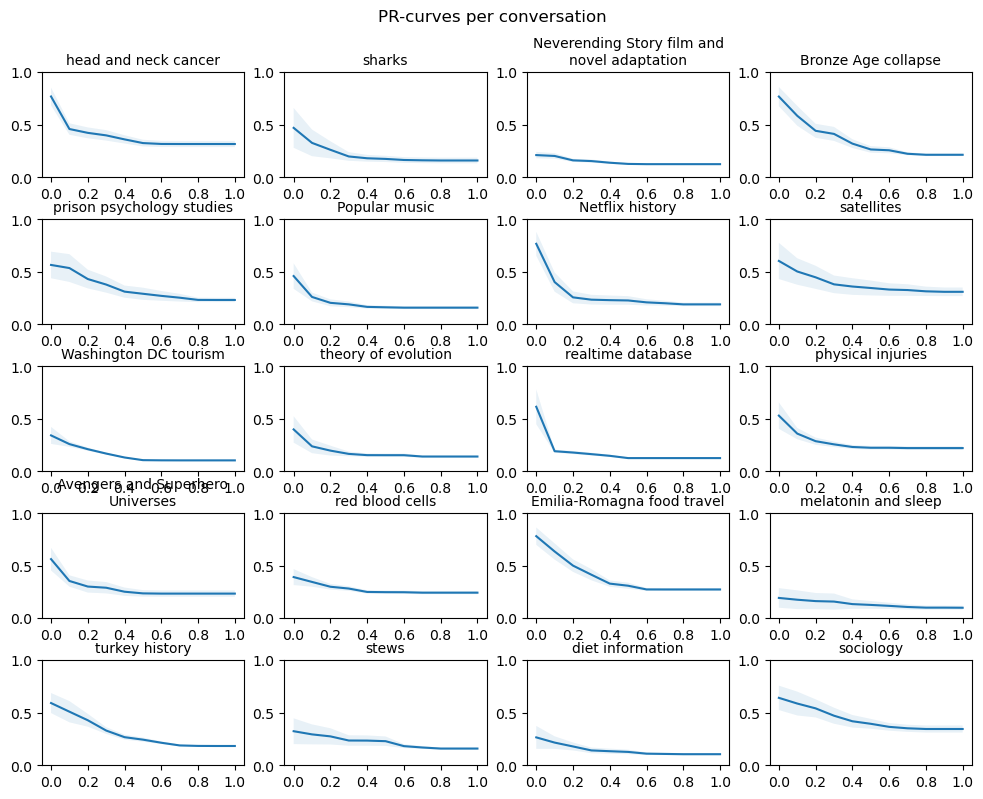

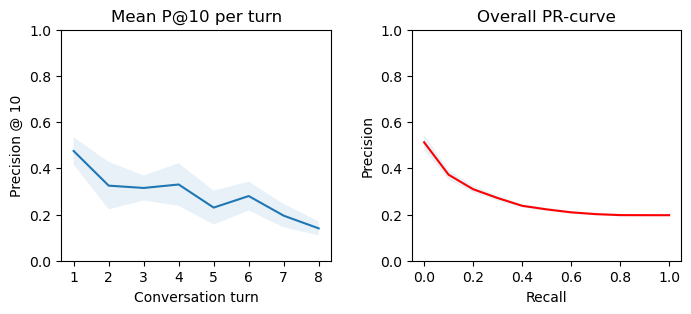

In [8]:
from retrieval.ConversationHistory import ConversationHistory

convHistory = ConversationHistory(opensearch,test_bed,conv_topics,selected_topics)
convHistory.run_sliding_window(fig_subplot_size)

Conversation History - First utterance only

c:\Users\Grave\Documents\GitHub\RI-Project\1st Stage\NLPSearch-phase1\retrieval\ConversationHistory.py:136: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



QUERY: What is a physician's assistant? What are the educational requirements required to become one?


QUERY: What is a physician's assistant? What does it cost?


QUERY: What is a physician's assistant? What's the average starting salary in the UK?


QUERY: What is a physician's assistant? What about in the US?


QUERY: What is a physician's assistant? What school subjects are needed to become a registered nurse?


QUERY: What is a physician's assistant? What is the PA average salary vs an RN?


QUERY: What is a physician's assistant? What the difference between a PA and a nurse practitioner?


QUERY: What is a physician's assistant? Do NPs or PAs make more?


QUERY: What is a physician's assistant? Is a PA above a NP?


QUERY: What is a physician's assistant? What is the fastest way to become a NP?


QUERY: What is a physician's assistant? How much longer does it take to become a doctor after being an NP?


QUERY: What are the main breeds of goat? Tell me about boer goats.


QUERY:

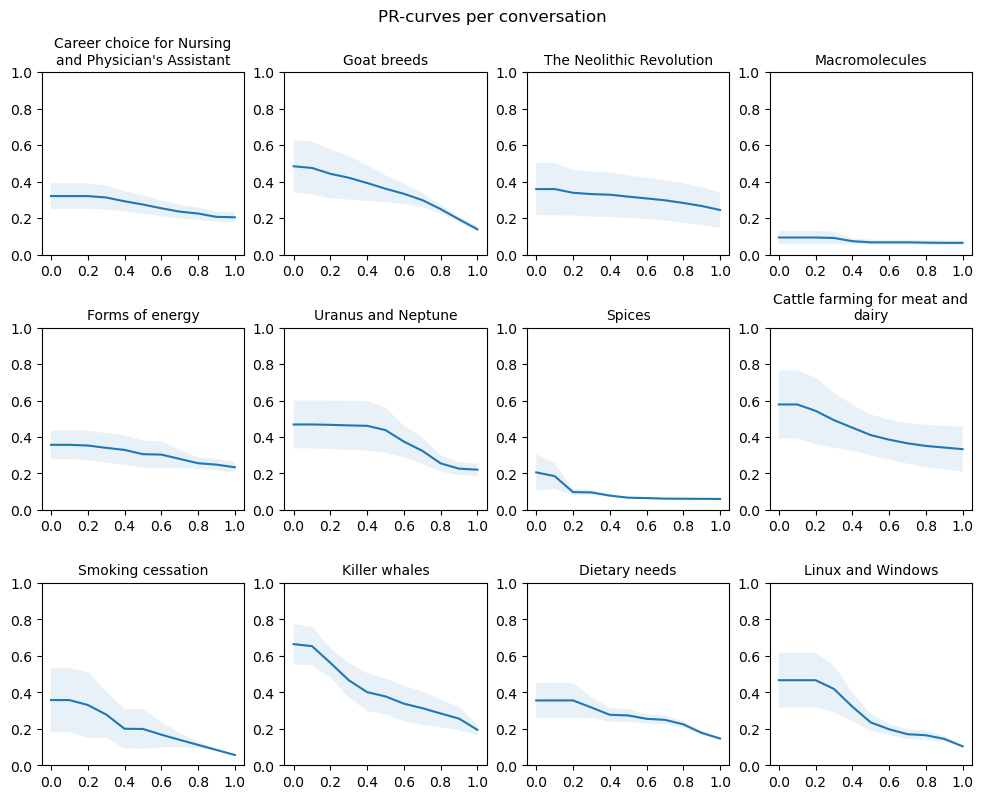

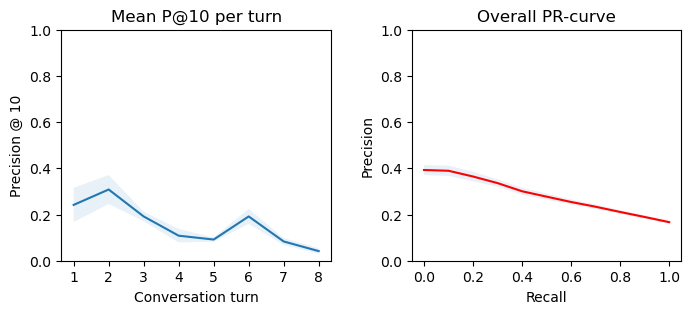

In [4]:
from retrieval.ConversationHistory import ConversationHistory

convHistory = ConversationHistory(opensearch,test_bed,conv_topics,selected_topics)
convHistory.run_first_utt_only(fig_subplot_size)

c:\Users\Grave\Documents\GitHub\RI-Project\1st Stage\NLPSearch-phase1\retrieval\ConversationHistoryLlama.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


   _index _type                                           _id     _score  \
0    kwiz  _doc                                 MARCO_3951096  22.857110   
1    kwiz  _doc                                  MARCO_849267  21.770878   
2    kwiz  _doc                                  MARCO_920443  21.770878   
3    kwiz  _doc                                 MARCO_2307794  21.652912   
4    kwiz  _doc                                 MARCO_4389107  14.715845   
..    ...   ...                                           ...        ...   
95   kwiz  _doc  CAR_e547a542463cd03cadad9a8c2b879adaadd79498   6.848598   
96   kwiz  _doc                                 MARCO_3984224   6.829070   
97   kwiz  _doc                                 MARCO_2486726   6.754774   
98   kwiz  _doc                                 MARCO_5417120   6.709174   
99   kwiz  _doc                                 MARCO_5690791   6.642787   

                                     _source.contents  \
0   What is the difference bet

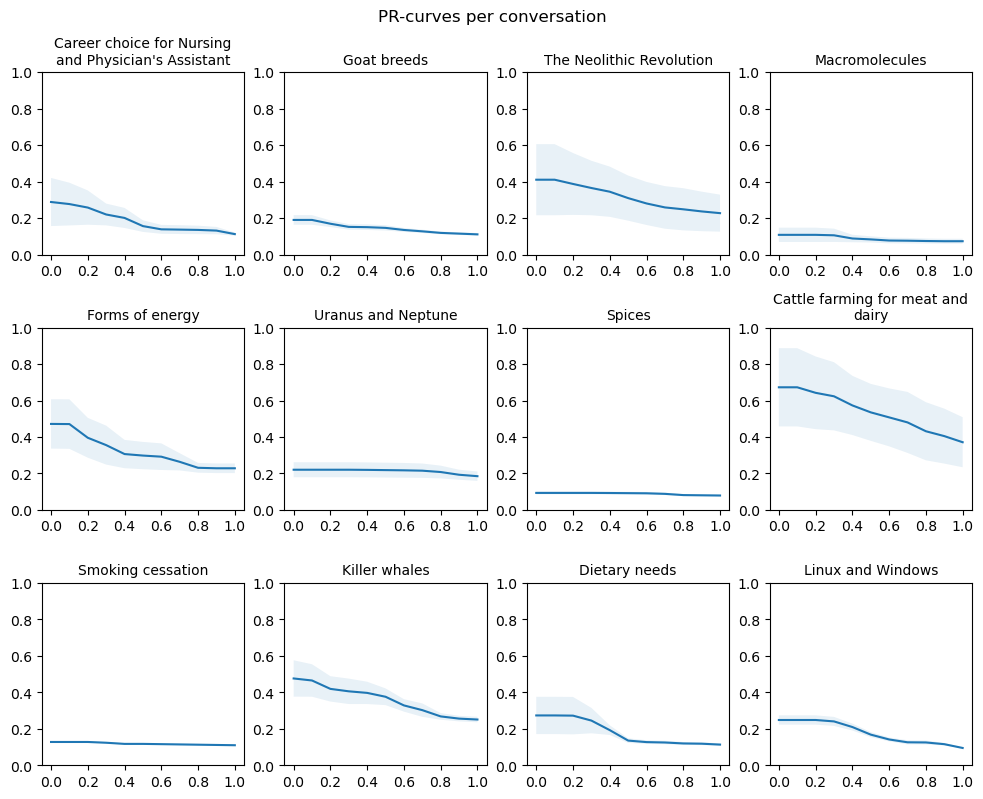

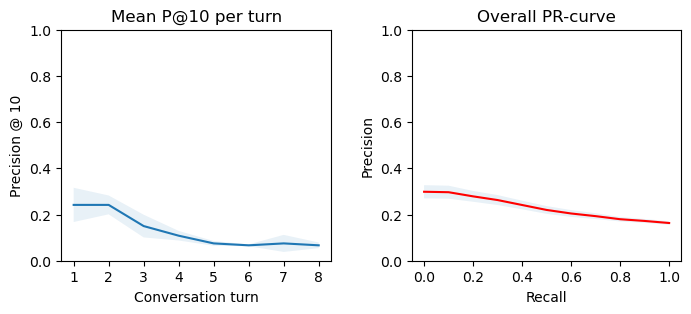

In [4]:
from retrieval.ConversationHistoryLlama import ConversationHistoryLlama

convHistoryLlama = ConversationHistoryLlama(opensearch,test_bed,conv_topics,selected_topics)
convHistoryLlama.run_sliding_window(fig_subplot_size)